# Resultados

Este archivo contiene todos los resultados del proyecto, con figuras y numeros que después seran utilizadas en el informe.

## Imports

In [1]:
from ppg_tools import *
import numpy as np

# Cargando los datos

(1768, 5, 1000) (1328, 5, 1000)
12 10


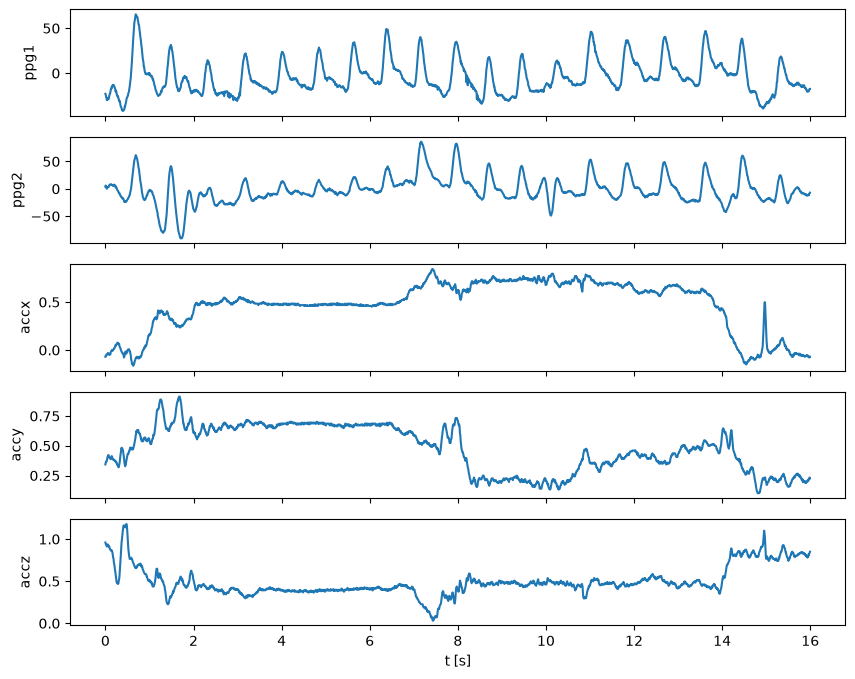

In [2]:
# Archivos en la misma carpeta que el notebook:
PATH_TRAIN = "IEEEPPG_TRAIN.ts"
PATH_TEST = "IEEEPPG_TEST.ts"

X_tr, y_tr = load_ts(PATH_TRAIN)
X_te, y_te = load_ts(PATH_TEST)
print(X_tr.shape, X_te.shape)          # (1768, 5, 1000) y (1328, 5, 1000)

recs_train = reconstruct_recordings(X_tr, y_tr)
recs_test = reconstruct_recordings(X_te, y_te)
print(len(recs_train), len(recs_test))  # 12 y 10

# Opcional: guardar para no repetir el paso lento la próxima vez
save_recordings(recs_train, "recordings_train.npz")
save_recordings(recs_test, "recordings_test.npz")
# y para recargar después:
# recs_train = load_recordings("recordings_train.npz")
# recs_test  = load_recordings("recordings_test.npz")

# Ejemplo de uso: una grabación, PPG filtrada y acelerómetro como referencias
r = recs_train[0]
ppg = bandpass(r["x"][:2])             # (2, N), canales ppg1 y ppg2
acc = bandpass(r["x"][2:])             # (3, N), ejes x, y, z
bpm_ref = r["bpm"]                      # un valor por ventana de 8 s, avanzando de a 2 s

# Gráfico para confirmar el orden de los canales
t = np.arange(r["x"].shape[1]) / FS
fig, axes = plt.subplots(5, 1, figsize=(10, 8), sharex=True)
for c, ax in enumerate(axes):
    ax.plot(t[:2000], r["x"][c, :2000])
    ax.set_ylabel(CH_NAMES[c])
axes[-1].set_xlabel("t [s]")
plt.show()

# Calculando el BPM sin LMS 

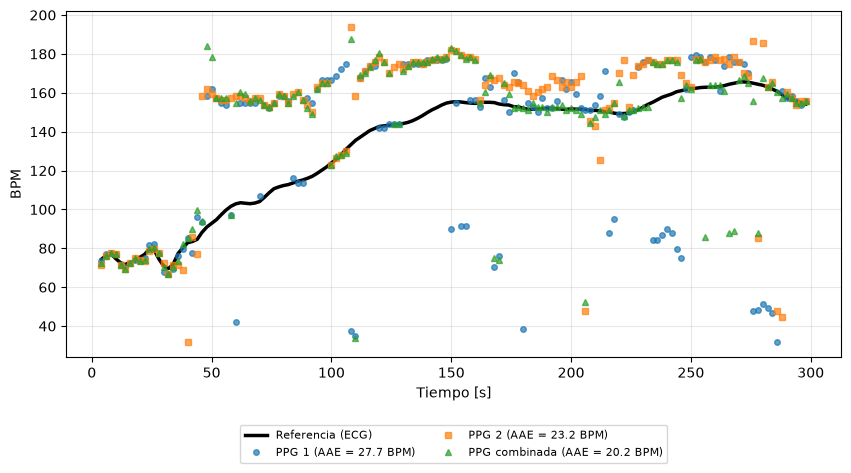

In [3]:
ppg1, ppg2 = ppg
ppg_combinado = (ppg1 + ppg2) / 2

#calculando el bpm de cada señal de ppg sin nada
est_1 = bpm_series(ppg1)
est_2 = bpm_series(ppg2)   
est_combinado = bpm_series(ppg_combinado)

#obteniendo el bpm de referencia de la grabación
bpm_ref = r["bpm"]

#Calculando el error de cada estimación
error_1 = np.abs(est_1 - bpm_ref)
error_2 = np.abs(est_2 - bpm_ref)
error_combinado = np.abs(est_combinado - bpm_ref)

# Eje de tiempo: centro de cada ventana de 8 s, que avanza de a 2 s
t = np.arange(len(bpm_ref)) * STEP / FS + (WIN / FS) / 2

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(t, bpm_ref, "k-", lw=2.5, label="Referencia (ECG)")
for est, nombre, marca in ((est_1, "PPG 1", "o"),
                           (est_2, "PPG 2", "s"),
                           (est_combinado, "PPG combinada", "^")):
    aae = np.mean(np.abs(est - bpm_ref))
    ax.plot(t, est, marca, ms=4, alpha=0.7, label=f"{nombre} (AAE = {aae:.1f} BPM)")

ax.set_xlabel("Tiempo [s]")
ax.set_ylabel("BPM")
ax.grid(alpha=0.3)
ax.legend(ncol=2, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.savefig("bpm_referencia_vs_estimado.pdf", bbox_inches="tight")
plt.show()


# Aplicando Monte Carlos para cada metodo para asegurar convergencia

In [4]:
# ---------------- configuración ----------------
N = 6000          # muestras por corrida (48 s a 125 Hz)
M_true = 12       # largo real del camino del artefacto
M = 12            # orden del filtro (M = M_true: el filtro puede modelar el camino exacto)
rho = 4.0         # potencia del artefacto / potencia del latido
sigma_v = 0.1     # desvío del ruido blanco (potencia 0.01)
K = 100           # corridas de Monte Carlo
X_GRID = np.sort(np.concatenate([np.logspace(-2, -0.3, 6), np.linspace(0.5, 3.5, 13)]))  # x = mu * tr(R)

## Comparando las señales simuladas contra las reales

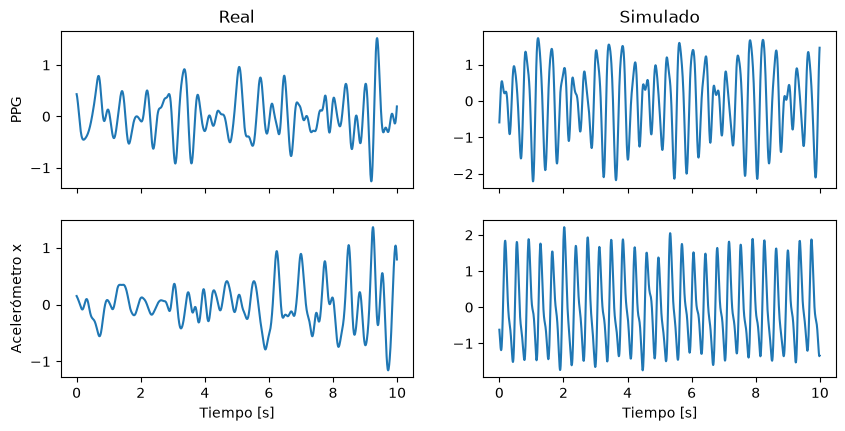

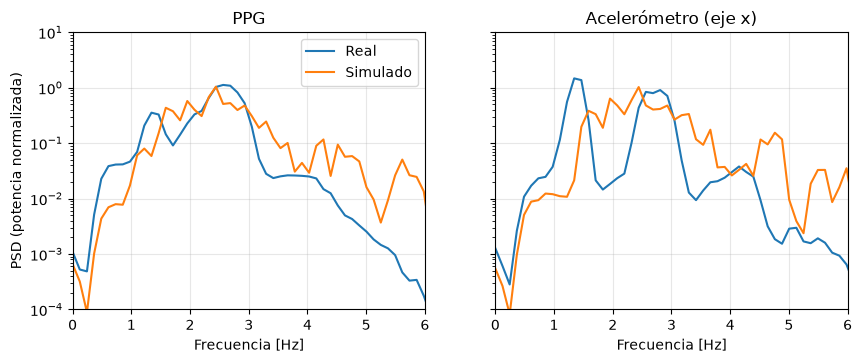

In [5]:
reales = [prepare_recording(r) for r in recs_train]                  # lista de (d, acc, bpm), ya filtrados y normalizados
sims = [escenario(k, N, M_true, rho, sigma_v) for k in range(30)]    # 30 escenarios simulados

# ---- 1) 10 segundos de señal: real contra simulada ----
n10 = 10 * FS
d_real, acc_real, _ = reales[0]
d_sim, acc_sim = norm(sims[0]["d"]), sims[0]["acc"]
t10 = np.arange(n10) / FS

fig, ax = plt.subplots(2, 2, figsize=(10, 4.5), sharex=True)
ax[0, 0].plot(t10, d_real[5000:5000 + n10]);       ax[0, 0].set_title("Real");     ax[0, 0].set_ylabel("PPG")
ax[1, 0].plot(t10, acc_real[0, 5000:5000 + n10]);  ax[1, 0].set_ylabel("Acelerómetro x")
ax[0, 1].plot(t10, d_sim[500:500 + n10]);          ax[0, 1].set_title("Simulado")
ax[1, 1].plot(t10, acc_sim[0, 500:500 + n10])
for a in ax[1]:
    a.set_xlabel("Tiempo [s]")
guardar("cmp_tiempo")
plt.show()

# ---- 2) espectro promedio (Welch), normalizado ----
grupos = [([r[0] for r in reales], [norm(e["d"]) for e in sims], "PPG"),
          ([r[1][0] for r in reales], [e["acc"][0] for e in sims], "Acelerómetro (eje x)")]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a, (senales_reales, senales_sim, titulo) in zip(ax, grupos):
    f, psd_real = psd_media(senales_reales)
    _, psd_sim = psd_media(senales_sim)
    a.semilogy(f, psd_real, label="Real")
    a.semilogy(f, psd_sim, label="Simulado")
    a.set_xlim(0, 6); a.set_ylim(1e-4, 1e1)
    a.set_title(titulo); a.set_xlabel("Frecuencia [Hz]"); a.grid(alpha=0.3)
ax[0].set_ylabel("PSD (potencia normalizada)")
ax[0].legend()
guardar("cmp_espectro")
plt.show()

Fracción de la PPG explicada por el acelerómetro
  real:      min 0.08 | mediana 0.26 | max 0.68
  simulado:  min 0.79 | mediana 0.80 | max 0.80
rho equivalente real = R2/(1-R2): mediana 0.36


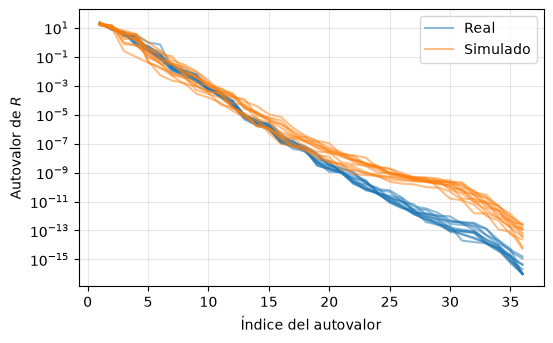

In [6]:
# fracción de la PPG que explica el acelerómetro y autovalores de R, en datos reales y simulados
res_real = [explicada_y_autovalores(d, acc, M) for d, acc, _ in reales]
res_sim = [explicada_y_autovalores(norm(e["d"]), e["acc"], M) for e in sims[:12]]

R2_real = np.array([r[0] for r in res_real])
R2_sim = np.array([r[0] for r in res_sim])
print("Fracción de la PPG explicada por el acelerómetro")
print("  real:      min %.2f | mediana %.2f | max %.2f" % (R2_real.min(), np.median(R2_real), R2_real.max()))
print("  simulado:  min %.2f | mediana %.2f | max %.2f" % (R2_sim.min(), np.median(R2_sim), R2_sim.max()))
print("rho equivalente real = R2/(1-R2): mediana %.2f" % np.median(R2_real / (1 - R2_real)))

fig, ax = plt.subplots(figsize=(6, 3.6))
for k, (_, lam) in enumerate(res_real):
    ax.semilogy(np.arange(1, len(lam) + 1), np.maximum(np.sort(lam)[::-1], 1e-16),
                c="C0", alpha=0.5, label="Real" if k == 0 else None)
for k, (_, lam) in enumerate(res_sim):
    ax.semilogy(np.arange(1, len(lam) + 1), np.maximum(np.sort(lam)[::-1], 1e-16),
                c="C1", alpha=0.5, label="Simulado" if k == 0 else None)
ax.set_xlabel("Índice del autovalor"); ax.set_ylabel(r"Autovalor de $R$")
ax.legend(); ax.grid(alpha=0.3)
guardar("cmp_autovalores")
plt.show()

## Estabilidad para diferentes valores de mu

tiempo: 548.6 s
x = mu*tr(R) máximo sin divergencias: {'LMS': 1.0, 'Newton-LMS': 1.0}
mu equivalente (con tr(R) medio = 36.0): {'LMS': 0.0278, 'Newton-LMS': 0.0278}


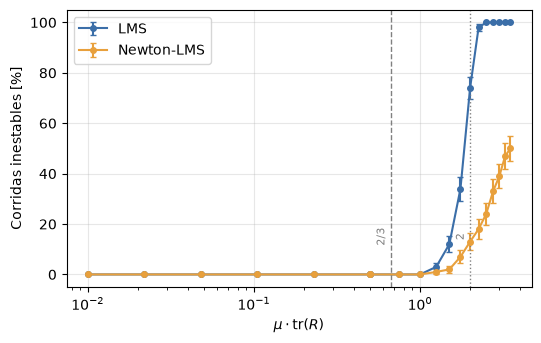

In [5]:
t0 = time.time()
trR_all = []
n_div = np.zeros((len(ALGOS), len(X_GRID)))
for seed in range(K):
    esc = escenario(seed, N, M_true, rho, sigma_v)
    prep = preparar(esc, M)
    trR_all.append(prep["trR"])
    for a, core in enumerate(ALGOS.values()):
        for j, x in enumerate(X_GRID):
            _, div = core(esc["d"], prep["U"], x / prep["trR"], prep["R_inv"])   # mu = x / tr(R)
            n_div[a, j] += div
print("tiempo:", round(time.time() - t0, 1), "s")

# mayor x = mu*tr(R) con 0 % de divergencia (contando desde la izquierda de la grilla)
x_estable = {}
for a, nombre in enumerate(ALGOS):
    hay_div = np.where(n_div[a] > 0)[0]
    j = hay_div[0] - 1 if len(hay_div) else len(X_GRID) - 1   # último x antes de la primera divergencia
    x_estable[nombre] = X_GRID[j] if j >= 0 else np.nan
trR_medio = np.mean(trR_all)
mu_estable = {n: x / trR_medio for n, x in x_estable.items()}
print("x = mu*tr(R) máximo sin divergencias:", {n: round(float(x), 3) for n, x in x_estable.items()})
print("mu equivalente (con tr(R) medio = %.1f):" % trR_medio, {n: float(f"{m:.2e}") for n, m in mu_estable.items()})

import json
with open("figuras_mc/A_x_estable.json", "w") as f:
    json.dump({"x_estable": {n: float(x) for n, x in x_estable.items()},
               "trR_medio": float(trR_medio), "K": K, "M": M}, f)

COLORES = {"LMS": "#3B6EA8", "Newton-LMS": "#E8A03C"}
fig, ax = plt.subplots(figsize=(6, 3.6))
for a, nombre in enumerate(ALGOS):
    p = n_div[a] / K
    ax.errorbar(X_GRID, 100 * p, yerr=100 * np.sqrt(p * (1 - p) / K),
                marker="o", ms=4, capsize=2, label=nombre, color=COLORES[nombre])
ax.axvline(2/3, ls="--", c="gray", lw=1); ax.axvline(2, ls=":", c="gray", lw=1)
ax.text(2/3 * 0.95, 15, "2/3", rotation=90, ha="right", va="center", fontsize=8, color="gray")
ax.text(2 * 0.95, 15, "2", rotation=90, ha="right", va="center", fontsize=8, color="gray")
ax.set_xscale("log"); ax.set_xlabel(r"$\mu \cdot \mathrm{tr}(R)$"); ax.set_ylabel("Corridas inestables [%]")
ax.grid(alpha=0.3); ax.legend()
guardar("A_estabilidad")
plt.show()

## Velocidad de convergencia

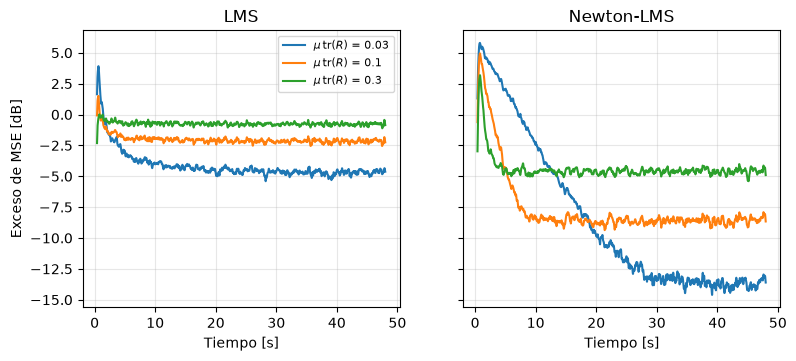

     x |         LMS |  Newton-LMS   (tiempo [s] para bajar 10 dB)
  0.03 |         nan |         nan
   0.1 |         nan |         nan
   0.3 |         nan |         nan


In [6]:
X_B = [0.03, 0.1, 0.3]    # valores de mu*tr(R) a comparar (todos en la zona estable de A)
VENTANA = 50              # suavizado de la curva promedio [muestras]

# promedio sobre las corridas de (e - s)^2 en cada instante n
curva = np.zeros((len(ALGOS), len(X_B), N))
n_ok = np.zeros((len(ALGOS), len(X_B)))
for seed in range(K):
    esc = escenario(seed, N, M_true, rho, sigma_v)
    prep = preparar(esc, M)
    for a, core in enumerate(ALGOS.values()):
        for j, x in enumerate(X_B):
            e, div = core(esc["d"], prep["U"], x / prep["trR"], prep["R_inv"])
            if not div:                                  # las divergidas no se promedian
                curva[a, j] += (e - esc["s"])**2
                n_ok[a, j] += 1
J = curva / n_ok[..., None]       # promedio sobre las corridas
J_ex = J - sigma_v**2             # exceso de MSE: lo que supera el piso del ruido v

def suavizar(y, w=VENTANA):       # suavizar DESPUÉS de promediar
    return np.convolve(y, np.ones(w) / w, mode="valid")

t_s = (np.arange(N - VENTANA + 1) + VENTANA - 1) / FS
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for a, ax in enumerate(axs):
    for j, x in enumerate(X_B):
        y = 10 * np.log10(np.maximum(suavizar(J_ex[a, j]), 1e-6))
        ax.plot(t_s, y, label=rf"$\mu\,\mathrm{{tr}}(R)$ = {x:g}")
    ax.set_title(list(ALGOS)[a]); ax.set_xlabel("Tiempo [s]"); ax.grid(alpha=0.3)
axs[0].set_ylabel("Exceso de MSE [dB]"); axs[0].legend(fontsize=8)
guardar("B_curvas_aprendizaje")
plt.show()

# tiempo que tarda el exceso de MSE en bajar 10 dB respecto de su valor inicial
def t_conv(j_ex, dB=10):
    y = suavizar(j_ex)
    umbral = j_ex[:20].mean() * 10 ** (-dB / 10)         # valor inicial (w = 0) reducido en dB
    idx = np.where(y <= umbral)[0]
    return (idx[0] + VENTANA - 1) / FS if len(idx) else np.nan   # nan = no lo alcanzó

print(f"{'x':>6} | " + " | ".join(f"{n:>11}" for n in ALGOS) + "   (tiempo [s] para bajar 10 dB)")
for j, x in enumerate(X_B):
    print(f"{x:6g} | " + " | ".join(f"{t_conv(J_ex[a, j]):11.1f}" for a in range(len(ALGOS))))

In [ ]:
Ms = [4, 8, 12, 16, 24, 32, 48]
X_ORDEN = 0.03                                   # mu * tr(R) fijo
res = {a: np.zeros((len(Ms), K)) for a in ALGOS}
for seed in range(K):
    esc = escenario(seed, N, M_true, rho, sigma_v)
    for i, M in enumerate(Ms):
        prep = preparar(esc, M)                  # con M distinto de M_true, U cambia
        for a, core in ALGOS.items():
            # TODO: correr core con mu = X_ORDEN / prep["trR"]
            # TODO: guardar mean((e - s)[-N//4:]**2), o np.inf si divergió